# Deepfake Detection: Data Loading

**Dataset:** Tiny-GenImage (Hugging Face), real photographs and AI-generated images from eight generators.

In [11]:
from datasets import load_dataset

# Streamed rather than downloaded: the full dataset is ~8 GB.
ds = load_dataset("TheKernel01/Tiny-GenImage", split="train", streaming=True)

print(ds.features)

{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['real', 'fake']), 'generator': ClassLabel(names=['Real', 'ADM', 'BigGAN', 'GLIDE', 'Midjourney', 'SD14', 'SD15', 'VQDM', 'Wukong'])}


## 2. Exploring the data

In [12]:
import pandas as pd

# Metadata only (no images) for the first 2,000 rows.
meta = ds.select_columns(["label", "generator"])
df = pd.DataFrame(list(meta.take(2000)))

df["label_name"] = df["label"].map(ds.features["label"].int2str)
df["generator_name"] = df["generator"].map(ds.features["generator"].int2str)

df.shape

(2000, 4)

In [3]:
df.head()

,label,generator,label_name,generator_name
0,0,0,real,Real
1,1,1,fake,ADM
2,0,0,real,Real
3,1,2,fake,BigGAN
4,0,0,real,Real


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   label           2000 non-null   int64
 1   generator       2000 non-null   int64
 2   label_name      2000 non-null   str  
 3   generator_name  2000 non-null   str  
dtypes: int64(2), str(2)
memory usage: 79.6 KB


In [5]:
print(df["label_name"].value_counts())
print(df["generator_name"].value_counts())

label_name
real    1000
fake    1000
Name: count, dtype: int64
generator_name
Real          1000
ADM            143
BigGAN         143
GLIDE          143
Midjourney     143
SD15           143
VQDM           143
Wukong         142
Name: count, dtype: int64


## 3. Building the image subset

In [6]:
import numpy as np

want = {"Real": 525, "SD15": 375, "Midjourney": 150}
got = {"Real": [], "SD15": [], "Midjourney": []}

names = ds.features["generator"].names

for row in ds:
    gen = names[row["generator"]]
    if gen not in got or len(got[gen]) >= want[gen]:
        continue
    img = row["image"].convert("RGB").resize((32, 32))
    got[gen].append(np.array(img))
    if all(len(got[k]) >= want[k] for k in want):
        break

for k in got:
    print(k, len(got[k]))

Real 525
SD15 375
Midjourney 150


Matplotlib is building the font cache; this may take a moment.


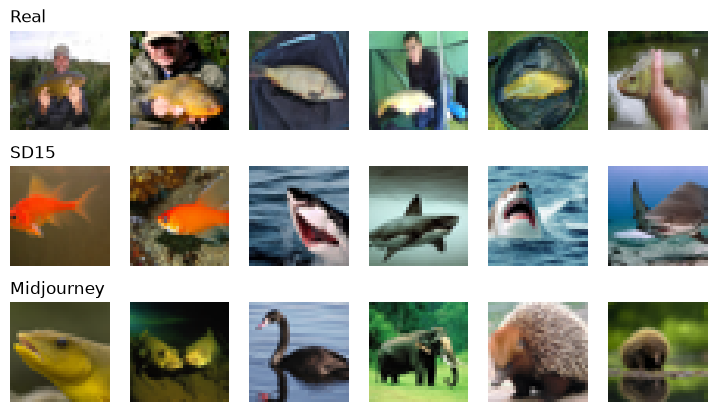

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 6, figsize=(9, 5))

for row_num, name in enumerate(["Real", "SD15", "Midjourney"]):
    for col_num in range(6):
        axes[row_num, col_num].imshow(got[name][col_num])
        axes[row_num, col_num].axis("off")
    axes[row_num, 0].set_title(name, loc="left")

plt.show()

## 4. Data integrity checks

In [8]:
all_imgs = got["Real"] + got["SD15"] + got["Midjourney"]

print("Total images:", len(all_imgs))
print("Shape of one image:", all_imgs[0].shape)
print("Smallest pixel value:", min(img.min() for img in all_imgs))
print("Largest pixel value:", max(img.max() for img in all_imgs))

# Duplicate check: identical images have identical bytes
unique = set(img.tobytes() for img in all_imgs)
print("Unique images:", len(unique))

for img in all_imgs:
    assert img.shape == (32, 32, 3)
print("All shape checks passed")

Total images: 1050
Shape of one image: (32, 32, 3)
Smallest pixel value: 0
Largest pixel value: 255
Unique images: 1050
All shape checks passed


## 5. Preprocessing and data split

In [9]:
# Scale pixel values from 0-255 down to 0-1
real = np.array(got["Real"]).astype("float32") / 255
sd15 = np.array(got["SD15"]).astype("float32") / 255
mj = np.array(got["Midjourney"]).astype("float32") / 255

# Shuffle with a fixed seed so the split is the same every time
rng = np.random.default_rng(42)
real = real[rng.permutation(len(real))]
sd15 = sd15[rng.permutation(len(sd15))]

# 0 = real, 1 = fake
X_train = np.concatenate([real[:225], sd15[:225]])
y_train = np.array([0] * 225 + [1] * 225)

X_val = np.concatenate([real[225:300], sd15[225:300]])
y_val = np.array([0] * 75 + [1] * 75)

X_test = np.concatenate([real[300:375], sd15[300:375]])
y_test = np.array([0] * 75 + [1] * 75)

X_gen = np.concatenate([real[375:525], mj])
y_gen = np.array([0] * 150 + [1] * 150)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Cross-generator test:", X_gen.shape, y_gen.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())

Train: (450, 32, 32, 3) (450,)
Validation: (150, 32, 32, 3) (150,)
Test: (150, 32, 32, 3) (150,)
Cross-generator test: (300, 32, 32, 3) (300,)
Pixel range: 0.0 to 1.0


In [10]:
import torch
from torch.utils.data import TensorDataset, DataLoader

def to_dataset(X, y):
    # (N, 32, 32, 3) -> (N, 3, 32, 32)
    X = torch.from_numpy(X).permute(0, 3, 1, 2)
    y = torch.from_numpy(y).float()
    return TensorDataset(X, y)

train_loader = DataLoader(to_dataset(X_train, y_train), batch_size=32, shuffle=True)
val_loader = DataLoader(to_dataset(X_val, y_val), batch_size=32)
test_loader = DataLoader(to_dataset(X_test, y_test), batch_size=32)
gen_loader = DataLoader(to_dataset(X_gen, y_gen), batch_size=32)

images, labels = next(iter(train_loader))
print("Batch of images:", images.shape)
print("Batch of labels:", labels.shape)

Batch of images: torch.Size([32, 3, 32, 32])
Batch of labels: torch.Size([32])


In [13]:
print(df.isna().sum())

for name, X in [("train", X_train), ("val", X_val), ("test", X_test), ("cross-gen", X_gen)]:
    print(name, "NaN:", np.isnan(X).sum(), "Inf:", np.isinf(X).sum())

for name, y in [("train", y_train), ("val", y_val), ("test", y_test), ("cross-gen", y_gen)]:
    print(name, "real:", (y == 0).sum(), "fake:", (y == 1).sum())

splits = {
    "train": set(x.tobytes() for x in X_train),
    "val": set(x.tobytes() for x in X_val),
    "test": set(x.tobytes() for x in X_test),
    "cross-gen": set(x.tobytes() for x in X_gen),
}
names_list = list(splits)
for i in range(len(names_list)):
    for j in range(i + 1, len(names_list)):
        shared = len(splits[names_list[i]] & splits[names_list[j]])
        print(names_list[i], "vs", names_list[j], "shared images:", shared)

label             0
generator         0
label_name        0
generator_name    0
dtype: int64
train NaN: 0 Inf: 0
val NaN: 0 Inf: 0
test NaN: 0 Inf: 0
cross-gen NaN: 0 Inf: 0
train real: 225 fake: 225
val real: 75 fake: 75
test real: 75 fake: 75
cross-gen real: 150 fake: 150
train vs val shared images: 0
train vs test shared images: 0
train vs cross-gen shared images: 0
val vs test shared images: 0
val vs cross-gen shared images: 0
test vs cross-gen shared images: 0


## 6. CNN baseline

In [14]:
import torch.nn as nn

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

cnn = SimpleCNN().to(device)

print("Device:", device)
print("Parameters:", sum(p.numel() for p in cnn.parameters()))
print("Output shape:", cnn(images.to(device)).shape)

Device: mps
Parameters: 89249
Output shape: torch.Size([32])


In [15]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(cnn.parameters(), lr=0.001)

def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, count = 0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(X)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += ((out > 0).float() == y).sum().item()
        count += len(y)
    return total_loss / count, correct / count

def evaluate(model, loader):
    model.eval()
    total_loss, correct, count = 0, 0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            total_loss += loss_fn(out, y).item() * len(y)
            correct += ((out > 0).float() == y).sum().item()
            count += len(y)
    return total_loss / count, correct / count

# Sanity check: the untrained model should be close to guessing
val_loss, val_acc = evaluate(cnn, val_loader)
print("Untrained model, validation loss:", round(val_loss, 3))
print("Untrained model, validation accuracy:", round(val_acc, 3))

Untrained model, validation loss: 0.694
Untrained model, validation accuracy: 0.5


In [16]:
import copy

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = 999
best_weights = None
bad_epochs = 0

for epoch in range(1, 31):
    train_loss, train_acc = train_one_epoch(cnn, train_loader)
    val_loss, val_acc = evaluate(cnn, val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch:2d} | train loss {train_loss:.3f}, acc {train_acc:.3f} | val loss {val_loss:.3f}, acc {val_acc:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(cnn.state_dict())
        bad_epochs = 0
    else:
        bad_epochs += 1
        if bad_epochs >= 5:
            print("Validation loss stopped improving, stopping early")
            break

cnn.load_state_dict(best_weights)
print("Best validation loss:", round(best_val_loss, 3))

Epoch  1 | train loss 0.699, acc 0.500 | val loss 0.694, acc 0.500
Epoch  2 | train loss 0.694, acc 0.500 | val loss 0.693, acc 0.500
Epoch  3 | train loss 0.692, acc 0.500 | val loss 0.690, acc 0.500
Epoch  4 | train loss 0.684, acc 0.551 | val loss 0.666, acc 0.707
Epoch  5 | train loss 0.633, acc 0.687 | val loss 0.687, acc 0.573
Epoch  6 | train loss 0.586, acc 0.680 | val loss 0.563, acc 0.713
Epoch  7 | train loss 0.513, acc 0.753 | val loss 0.510, acc 0.747
Epoch  8 | train loss 0.491, acc 0.778 | val loss 0.496, acc 0.753
Epoch  9 | train loss 0.468, acc 0.769 | val loss 0.517, acc 0.747
Epoch 10 | train loss 0.451, acc 0.771 | val loss 0.506, acc 0.727
Epoch 11 | train loss 0.447, acc 0.782 | val loss 0.472, acc 0.773
Epoch 12 | train loss 0.422, acc 0.809 | val loss 0.468, acc 0.760
Epoch 13 | train loss 0.404, acc 0.818 | val loss 0.471, acc 0.760
Epoch 14 | train loss 0.387, acc 0.824 | val loss 0.527, acc 0.720
Epoch 15 | train loss 0.437, acc 0.780 | val loss 0.473, acc 0

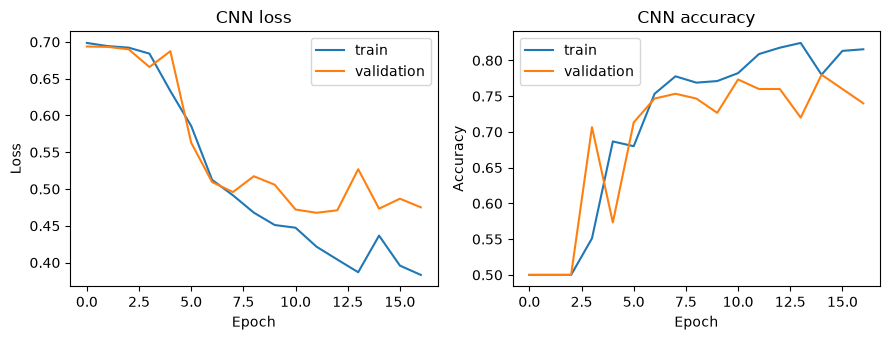

Saved the loss curve and the model weights


In [17]:
import os
import matplotlib.pyplot as plt

os.makedirs("../results", exist_ok=True)
os.makedirs("../models", exist_ok=True)

plt.figure(figsize=(9, 3.5))

plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="train")
plt.plot(history["val_acc"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN accuracy")
plt.legend()

plt.tight_layout()
plt.savefig("../results/cnn_loss_curve.png", dpi=150)
plt.show()

torch.save(cnn.state_dict(), "../models/cnn_baseline.pt")
print("Saved the loss curve and the model weights")